# 00 — Problem & Data | The Impostor

Notebook khám phá dữ liệu, JPEG heuristic, phân tích lỗi và chuẩn bị development split. Chạy bằng kernel Python của môi trường `uv` trong VS Code, từ thư mục gốc dự án hoặc `notebooks/`.

**Quy tắc:** không điều chỉnh mô hình dựa trên holdout; không ghi đè split có sẵn. Các kết quả JPEG tính trên toàn bộ train chỉ mang tính thăm dò.

## 1. Thiết lập môi trường và đường dẫn

**Mục tiêu:** import thư viện, dùng package `kemaodanh_oai`, xác định `PROJECT_ROOT` và tìm `pairs.csv`. Chạy trên VS Code với kernel `.venv` được quản lý bởi uv.


In [1]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split, StratifiedKFold

from kemaodanh_oai.data import load_pairs

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Tìm dataset theo các cấu trúc đã dùng trong dự án.
candidates = [
    PROJECT_ROOT / "data" / "data" / "train",
    PROJECT_ROOT / "data" / "train",
    PROJECT_ROOT / "data" / "data" / "data" / "train",
]
TRAIN_DIR = next((p for p in candidates if (p / "pairs.csv").is_file()), None)
if TRAIN_DIR is None:
    raise FileNotFoundError(f"Không tìm thấy train/pairs.csv trong: {candidates}")
CSV_PATH = TRAIN_DIR / "pairs.csv"
print("Dataset:", CSV_PATH)

Dataset: C:\Users\PC\Desktop\Python\KeMaoDanh-OAI\data\data\train\pairs.csv


## 2. Đọc và kiểm tra manifest

**Đầu vào:** `train/pairs.csv`. **Đầu ra:** DataFrame gồm `pair_id`, `image_0`, `image_1`, `fake_position`. `pair_id` cần giữ dạng chuỗi để không mất số 0 đầu.


In [2]:
df = load_pairs(CSV_PATH)

display(df.head())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Dtypes:")
print(df.dtypes)

,pair_id,image_0,image_1,fake_position
0,00001,images/00295.jpg,images/01131.jpg,1
1,00002,images/00684.jpg,images/00888.jpg,0
2,00003,images/00016.jpg,images/00059.jpg,0
3,00004,images/01000.jpg,images/00449.jpg,1
4,00005,images/01117.jpg,images/01089.jpg,1


Shape: (1000, 4)
Columns: ['pair_id', 'image_0', 'image_1', 'fake_position']
Dtypes:
pair_id            str
image_0            str
image_1            str
fake_position    int64
dtype: object


### 2.1. Phân bố nhãn

`fake_position=0` nghĩa là ảnh 0 giả, `1` nghĩa là ảnh 1 giả. Dùng `value_counts()` để kiểm tra cân bằng nhãn; biểu đồ chỉ phản ánh vị trí ảnh giả.


fake_position
0    500
1    500
Name: count, dtype: int64


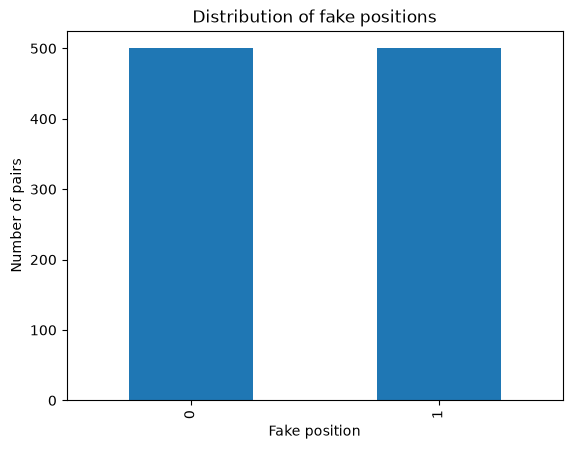

In [3]:
label_counts = df["fake_position"].value_counts().sort_index()

print(label_counts)

label_counts.plot(kind="bar")
plt.xlabel("Fake position")
plt.ylabel("Number of pairs")
plt.title("Distribution of fake positions")
plt.show()

## 3. Trực quan hóa các cặp ảnh

**Mục tiêu:** xem ảnh 0 và ảnh 1 cạnh nhau, đối chiếu nhãn. Đường dẫn trong CSV đã chứa `images/`, vì vậy ghép với `TRAIN_DIR` chứ không thêm `images/` lần nữa.


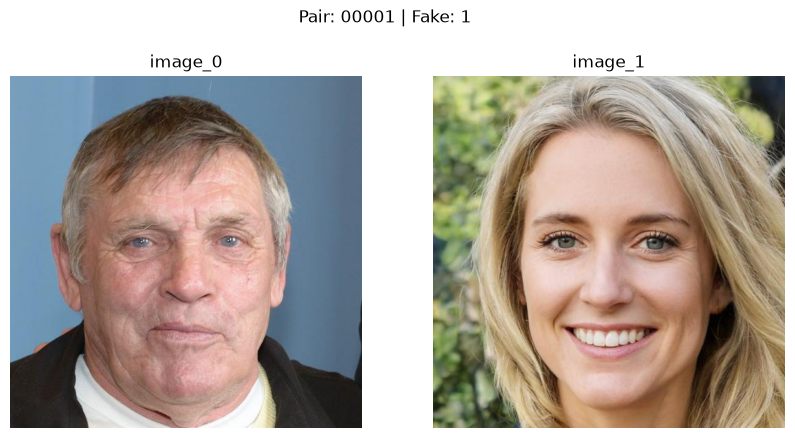

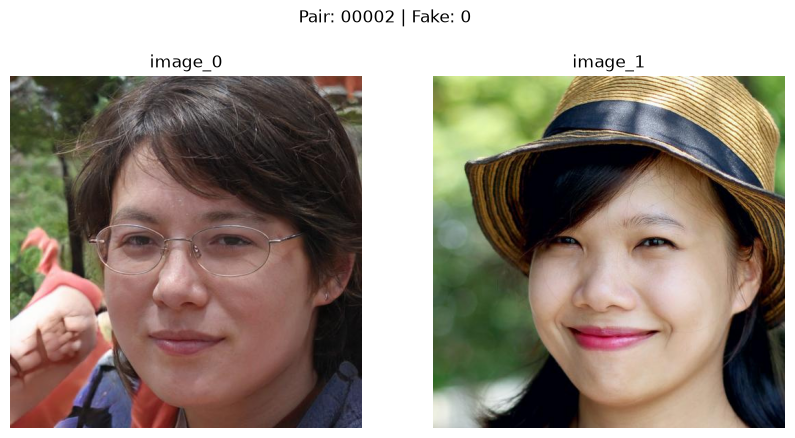

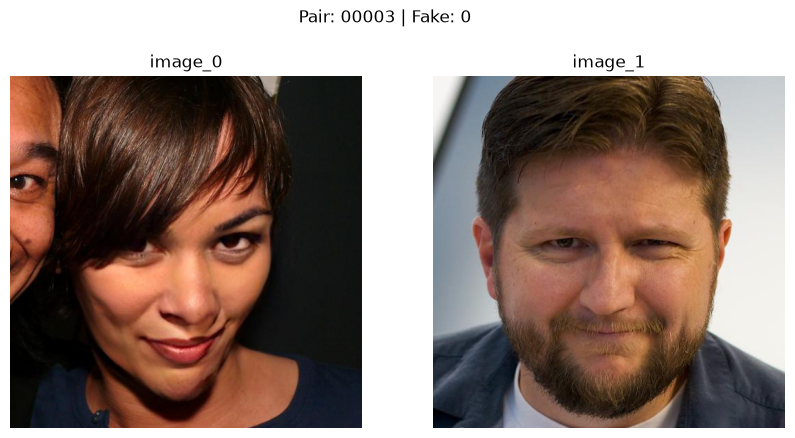

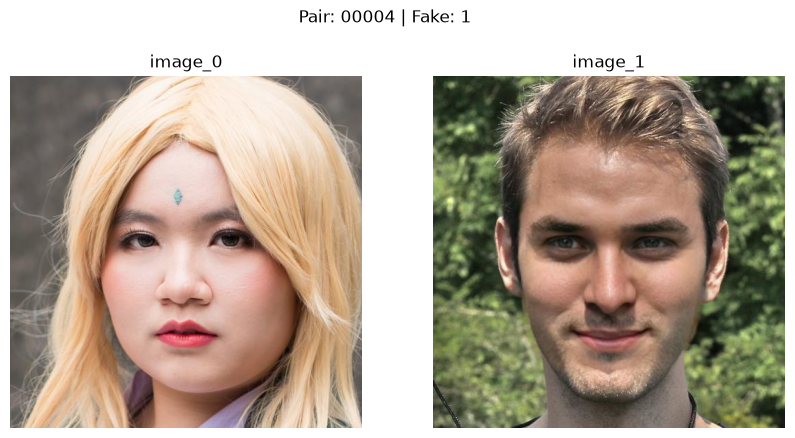

In [4]:
def show_pair(row, image_dir):
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    columns = ["image_0", "image_1"]

    for i, column in enumerate(columns):
        image_path = image_dir / row[column]

        with Image.open(image_path) as img:
            rgb_img = img.convert("RGB")

        axes[i].imshow(rgb_img)
        axes[i].set_title(column)
        axes[i].axis("off")

    plt.suptitle(
        f"Pair: {row['pair_id']} | Fake: {row['fake_position']}"
    )
    plt.show()

show_pair(df.iloc[0], TRAIN_DIR)
show_pair(df.iloc[1], TRAIN_DIR)
show_pair(df.iloc[2], TRAIN_DIR)
show_pair(df.iloc[3], TRAIN_DIR)

## 4. Image Inventory

### 4.1. Đọc metadata của một ảnh
`Image.open(...).size` trả về `(width, height)` theo pixel; `Path.stat().st_size` trả về số byte trên đĩa. Hàm này không phân loại ảnh.


In [5]:
def get_image_info(image_path):
    img_path = Path(image_path)

    with Image.open(img_path) as img:
        width, height = img.size

    file_size = img_path.stat().st_size

    return {"width": width, "height": height, "file_size": file_size}

### 4.2. Tạo bảng metadata cho toàn bộ ảnh

Duyệt từng cặp, sau đó từng vị trí 0/1. `is_fake = int(position == fake_position)` gán nhãn cho từng **ảnh**, khác với nhãn của **cặp**. Kết quả kỳ vọng: 2.000 dòng cho 1.000 cặp.


In [6]:
def build_image_inventory(df, train_dir):
    records = []
    for _, row in df.iterrows():
        for position, column in enumerate(["image_0", "image_1"]):
            img_path = train_dir / row[column]
            get_info= get_image_info(img_path)

            is_fake = int(position == row["fake_position"])

            record = {
                "pair_id" : row["pair_id"],
                "image_name": row[column],
                "image_position": position,
                "is_fake" : is_fake,
                "width" : get_info["width"],
                "height" : get_info["height"],
                "file_size" : get_info["file_size"]
            }

            records.append(record)

    inventory_df = pd.DataFrame(records)
    return inventory_df

inventory = build_image_inventory(df, TRAIN_DIR)
display(inventory.head())

,pair_id,image_name,image_position,is_fake,width,height,file_size
0,00001,images/00295.jpg,0,0,512,512,63800
1,00001,images/01131.jpg,1,1,512,512,90053
2,00002,images/00684.jpg,0,1,512,512,81391
3,00002,images/00888.jpg,1,0,512,512,86832
4,00003,images/00016.jpg,0,1,512,512,72605


### 4.3. Thống kê dung lượng theo ảnh thật/giả

Dùng `groupby("is_fake").describe()` để xem số lượng, trung bình, độ lệch chuẩn và các phân vị. Chưa thể kết luận dung lượng là dấu hiệu phổ quát của ảnh AI.


In [7]:
inventory.groupby("is_fake")["file_size"].describe()

,count,mean,std,min,25%,50%,75%,max
is_fake,,,,,,,,
0,1000.0,78065.563,13849.484797,43474.0,68272.25,77444.0,86257.25,147769.0
1,1000.0,65370.089,14410.705349,32609.0,54979.25,65498.0,75168.50,113748.0


### 4.4. Dung lượng trung bình theo KiB

Chia số byte cho 1024 để đổi sang KiB. Đây là thống kê mô tả, không phải kết quả dự đoán.


In [8]:
mean_size = inventory.groupby("is_fake")["file_size"].mean() / 1024

print("Real mean size:", mean_size[0], "Kib")
print("Fake mean size:", mean_size[1], "Kib")

Real mean size: 76.2359013671875 Kib
Fake mean size: 63.8379775390625 Kib


### 4.5. Histogram dung lượng JPEG

So sánh hai phân bố thực/giả và vùng chồng lấn. Sự khác biệt có thể liên quan tới pipeline tạo và nén ảnh; không chứng minh quan hệ nhân quả.


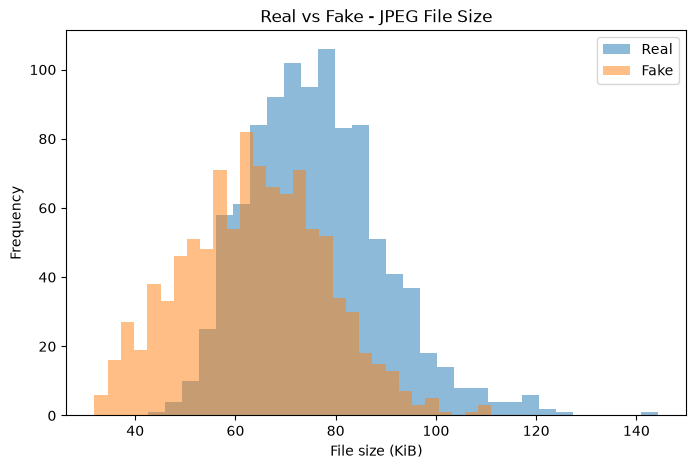

In [9]:
plt.figure(figsize=(8, 5))

for label, name in [(0, "Real"), (1, "Fake")]:
    subset = inventory[inventory["is_fake"] == label]

    plt.hist(
        subset["file_size"] / 1024,
        bins=30,
        alpha=0.5,
        label=name
    )

plt.xlabel("File size (KiB)")
plt.ylabel("Frequency")
plt.title("Real vs Fake - JPEG File Size")
plt.legend()
plt.show()

### JPEG heuristic — exploratory only

Giả thuyết: ảnh có file JPEG nhỏ hơn là ảnh giả. Heuristic này không cần training; kết quả trên toàn bộ 1.000 cặp chỉ minh họa mối liên hệ trong dữ liệu, không phải hiệu năng tổng quát hóa.

### 5.1. Đưa metadata về dạng từng cặp

`pivot()` tạo hai cột `size_0`, `size_1` trên mỗi `pair_id`. Mỗi cặp phải có đúng một giá trị ở mỗi vị trí.


In [10]:
pair_size = inventory.pivot(
    index="pair_id",
    columns="image_position",
    values="file_size"
)
pair_size.columns = ["size_0", "size_1"]
pair_size = pair_size.reset_index()
pair_size

,pair_id,size_0,size_1
0,00001,63800,90053
1,00002,81391,86832
2,00003,72605,70354
3,00004,78807,92346
4,00005,82252,68906
...,...,...,...
995,00996,85939,74990
996,00997,63314,77606
997,00998,67106,36209
998,00999,67694,76599


### 5.2. Quy tắc dự đoán không huấn luyện

Giả thuyết: ảnh có file JPEG nhỏ hơn là giả. Khi hai file bằng nhau, quy tắc hiện tại chọn vị trí 1. Đây là **heuristic**, không phải mô hình được fit.


In [11]:
pair_size["predicted"] = (
    pair_size["size_0"] >= pair_size["size_1"]
).astype(int)
pair_size

,pair_id,size_0,size_1,predicted
0,00001,63800,90053,0
1,00002,81391,86832,0
2,00003,72605,70354,1
3,00004,78807,92346,0
4,00005,82252,68906,1
...,...,...,...,...
995,00996,85939,74990,1
996,00997,63314,77606,0
997,00998,67106,36209,1
998,00999,67694,76599,0


### 5.3. Ghép nhãn thật và dự đoán

Ghép theo `pair_id` với `validate="one_to_one"` để bảo đảm mỗi cặp chỉ có một bản ghi. Không ghép theo thứ tự dòng.


In [12]:
results = pair_size.merge(
    df[["pair_id", "fake_position"]],
    on="pair_id",
    validate="one_to_one"
)
results

,pair_id,size_0,size_1,predicted,fake_position
0,00001,63800,90053,0,1
1,00002,81391,86832,0,0
2,00003,72605,70354,1,0
3,00004,78807,92346,0,1
4,00005,82252,68906,1,1
...,...,...,...,...,...
995,00996,85939,74990,1,0
996,00997,63314,77606,0,0
997,00998,67106,36209,1,1
998,00999,67694,76599,0,1


### 5.4. Accuracy, Macro-F1 và Confusion Matrix

Macro-F1 là trung bình F1 của hai lớp. Kết quả tại đây tính trên **toàn bộ 1.000 cặp train**, chỉ dùng khám phá; không được coi là validation hay holdout score.


In [13]:
y_pred = results["predicted"]
y_true = results["fake_position"]
print("Exploratory train Accuracy:", accuracy_score(y_true, y_pred))
print("Exploratory train Macro-F1:", f1_score(y_true, y_pred, average="macro"))
print(confusion_matrix(y_true, y_pred))

Exploratory train Accuracy: 0.727
Exploratory train Macro-F1: 0.7269866223444948
[[367 133]
 [140 360]]


## 6. Error Analysis

Lọc các cặp mà `predicted != fake_position`. Xem số lượng và đặc điểm của những trường hợp heuristic thất bại.


In [14]:
errors = results[
    results["predicted"] != results["fake_position"]
].copy()

print("Number of errors:", len(errors))
display(errors.head())

Number of errors: 273


,pair_id,size_0,size_1,predicted,fake_position
0,00001,63800,90053,0,1
2,00003,72605,70354,1,0
3,00004,78807,92346,0,1
8,00009,57399,66145,0,1
9,00010,62427,99680,0,1


### 6.1. Quan sát các cặp dự đoán sai

Hiển thị một số ví dụ để hình thành giả thuyết về texture, nén JPEG, nền và chi tiết; không kết luận nguyên nhân chỉ từ vài ảnh.


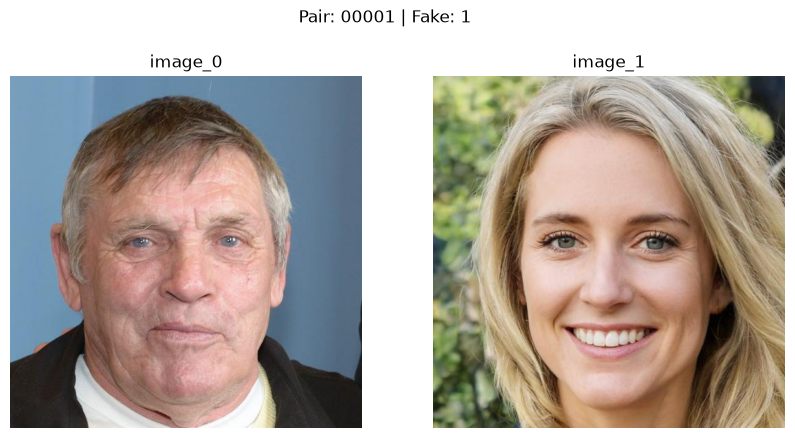

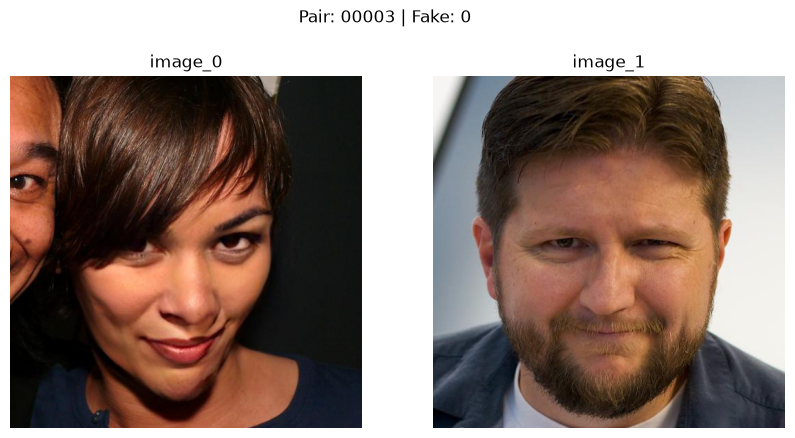

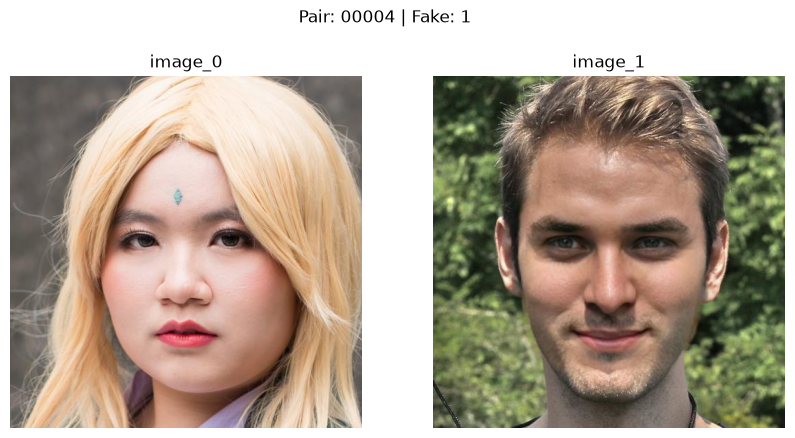

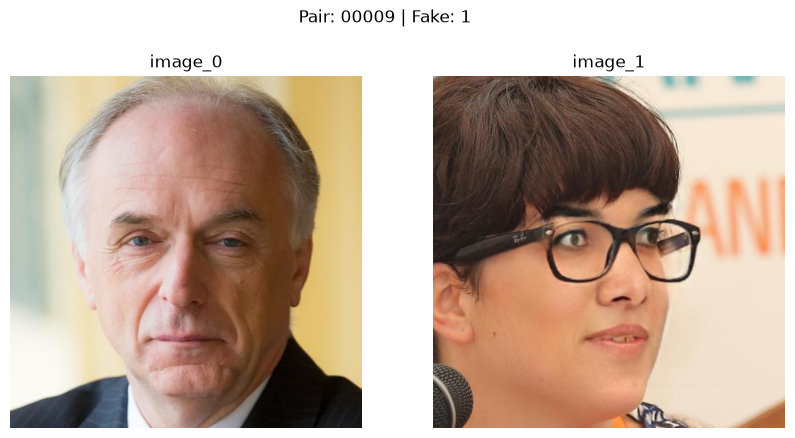

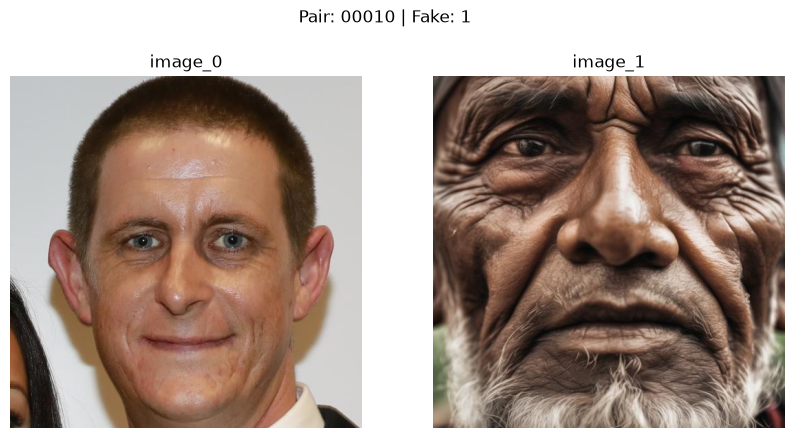

In [15]:
error_ids = errors["pair_id"].head(5)

for pair_id in error_ids:
    row = df.loc[df["pair_id"] == pair_id].iloc[0]
    show_pair(row, TRAIN_DIR)

## Development / Holdout (80/20) và 3-fold CV

**Nguyên tắc:** tạo split một lần rồi tái sử dụng. Nếu `configs/development_split.csv` đã tồn tại, notebook **không ghi đè**. Holdout chỉ dành cho đánh giá cuối cùng; baseline JPEG ở trên là EDA trên toàn bộ dữ liệu, **không** phải validation score.

> Lưu ý: split tự tạo có thể khác split tham chiếu của dự án gốc. Để tái lập đúng thí nghiệm gốc, cần dùng file split gốc.

### 7.1. Tạo split một lần và tái sử dụng

Chia 80% development và 20% holdout bằng stratification; development tiếp tục chia 3 fold. **Nếu file đã tồn tại, không ghi đè**. Đây là split tự tạo, có thể khác split tham chiếu trong ZIP gốc.


In [16]:
config_dir = PROJECT_ROOT / "configs"
config_dir.mkdir(parents=True, exist_ok=True)
split_path = config_dir / "development_split.csv"

if not split_path.exists():
    dev_df, holdout_df = train_test_split(
        df, test_size=0.2, random_state=42,
        stratify=df["fake_position"]
    )
    dev_df = dev_df.copy()
    dev_df["fold"] = -1
    skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    for fold, (_, val_idx) in enumerate(skf.split(dev_df, dev_df["fake_position"])):
        dev_df.iloc[val_idx, dev_df.columns.get_loc("fold")] = fold
    split_df = pd.concat([
        dev_df.assign(split="development"),
        holdout_df.assign(split="holdout", fold=-1),
    ], ignore_index=True)
    split_df[["pair_id", "split", "fold"]].to_csv(split_path, index=False)
    print("Created split:", split_path)
else:
    print("Using existing split (not overwritten):", split_path)

saved_split = pd.read_csv(split_path, dtype={"pair_id": str})

Using existing split (not overwritten): C:\Users\PC\Desktop\Python\KeMaoDanh-OAI\configs\development_split.csv


### 7.2. Kiểm tra tính toàn vẹn của split

Kiểm tra đủ `pair_id`, không trùng, không giao nhau giữa development/holdout, fold hợp lệ và số lượng 800/200. Các notebook sau đọc lại file này.


In [17]:
# Kiểm tra tính toàn vẹn của file split đã lưu
assert set(saved_split.columns) >= {"pair_id", "split", "fold"}
assert len(saved_split) == len(df)
assert saved_split["pair_id"].notna().all()
assert saved_split["pair_id"].is_unique
assert set(saved_split["pair_id"]) == set(df["pair_id"])
assert saved_split["fold"].notna().all()
assert set(saved_split["split"]) == {"development", "holdout"}

dev = saved_split[saved_split["split"] == "development"]
holdout = saved_split[saved_split["split"] == "holdout"]
assert len(dev) == 800 and len(holdout) == 200
assert set(dev["fold"]) == {0, 1, 2}
assert (holdout["fold"] == -1).all()
assert set(dev["pair_id"]).isdisjoint(set(holdout["pair_id"]))
print("Development split validation passed!")
print(dev["fold"].value_counts().sort_index())

Development split validation passed!
fold
0    267
1    267
2    266
Name: count, dtype: int64


### 7.3. Kiểm tra tỷ lệ nhãn theo fold

Bảng chéo cho biết mỗi fold có bao nhiêu nhãn 0 và 1. Stratified split cố gắng giữ tỷ lệ lớp cân bằng.


In [18]:
check_df = saved_split.merge(
    df[["pair_id", "fake_position"]], on="pair_id", validate="one_to_one"
)
print(pd.crosstab([check_df["split"], check_df["fold"]], check_df["fake_position"]))
assert check_df.groupby(["split", "fold"])["fake_position"].nunique().eq(2).all()

fake_position       0    1
split       fold          
development  0    133  134
             1    134  133
             2    133  133
holdout     -1    100  100


## 8. Kiểm tra trùng đường dẫn ảnh

Đếm tổng tham chiếu và số đường dẫn duy nhất. Không trùng tên **không có nghĩa** là nội dung ảnh không trùng.


In [19]:
all_images = pd.concat([df["image_0"], df["image_1"]], ignore_index=True)
print("Total image references:", len(all_images))
print("Unique image paths:", all_images.nunique())
print("Duplicated references:", all_images.duplicated().sum())

Total image references: 2000
Unique image paths: 2000
Duplicated references: 0


### 8.1. Kiểm tra trùng byte bằng SHA-256

Hash toàn bộ file để phát hiện nội dung byte giống hệt. SHA-256 không phát hiện ảnh giống nhau sau khi resize, nén lại hoặc chỉnh sửa. Chỉ cần chạy kiểm tra này một lần trên bộ dữ liệu hiện tại.


In [20]:
def calculate_sha256(image_path):
    sha256 = hashlib.sha256()
    with open(image_path, "rb") as file:
        for chunk in iter(lambda: file.read(65536), b""):
            sha256.update(chunk)
    return sha256.hexdigest()

inventory["sha256"] = inventory["image_name"].apply(
    lambda name: calculate_sha256(TRAIN_DIR / name)
)
print("Unique hashes:", inventory["sha256"].nunique())
print("Duplicate hashes:", inventory["sha256"].duplicated().sum())
print("SHA-256 chỉ phát hiện file giống hệt byte; không phát hiện ảnh gần giống.")

Unique hashes: 2000
Duplicate hashes: 0
SHA-256 chỉ phát hiện file giống hệt byte; không phát hiện ảnh gần giống.
